# Ask Ubuntu Dataset — Exploration
**ResolveX — M1: Project Research & Feasibility**

This notebook examines the Ask Ubuntu dataset to assess its structure, size, answer availability, tags, and temporal coverage.

The goal is to determine whether the dataset is suitable as a technical knowledge source for ResolveX's Ubuntu/Linux support prototype.

## 1. Setup

Import dependencies and configure paths. Reusable extraction logic is imported from `src/data/extraction.py`.

In [1]:
from pathlib import Path
import sys
import csv
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = next((folder for folder in (cwd, *cwd.parents)
             if (folder / "src" / "data" / "extraction.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the notebook within the ResolveX repository")
sys.path.insert(0, str(ROOT / "src"))
RAW = ROOT / "data" / "raw" / "Posts.xml"
QUESTIONS = ROOT / "data" / "interim" / "questions.csv"
ANSWERS = ROOT / "data" / "interim" / "answers.csv"

from data.extraction import preview_posts, extract_posts

## 2. Inspect the Source Structure

Preview a small sample of the raw XML without loading the entire file into memory.

In [2]:
if RAW.exists():
    for post in preview_posts(RAW, limit=3):
        print({key: (str(value)[:120] + "…" if len(str(value)) > 120 else value)
               for key, value in post.items() if key != "Body"})
else:
    print("Raw Posts.xml is not available locally; existing CSVs may still be analyzed.")

{'Id': '1', 'PostTypeId': '1', 'AcceptedAnswerId': '2', 'CreationDate': '2010-07-28T19:04:21.300', 'Score': '62', 'ViewCount': '4556', 'OwnerUserId': '5', 'LastEditorUserId': '208574', 'LastEditDate': '2014-12-16T01:47:45.980', 'LastActivityDate': '2018-10-05T23:56:48.997', 'Title': 'How to get the "Your battery is broken" message to go away?', 'Tags': '|power-management|notification|', 'AnswerCount': '4', 'CommentCount': '2', 'ContentLicense': 'CC BY-SA 3.0'}
{'Id': '2', 'PostTypeId': '2', 'ParentId': '1', 'CreationDate': '2010-07-28T19:15:30.357', 'Score': '41', 'OwnerUserId': '4', 'LastEditorUserId': '235', 'LastEditDate': '2012-07-30T13:51:42.147', 'LastActivityDate': '2012-07-30T13:51:42.147', 'CommentCount': '0', 'ContentLicense': 'CC BY-SA 3.0'}
{'Id': '3', 'PostTypeId': '1', 'AcceptedAnswerId': '258', 'CreationDate': '2010-07-28T19:21:50.653', 'Score': '51', 'ViewCount': '15799', 'OwnerUserId': '35', 'LastEditorUserId': '10581', 'LastEditDate': '2014-02-18T13:33:55.917', 'LastA

## 3. Extract Questions and Answers

Separate questions and answers from the raw XML dump into individual CSV files.

Extraction runs only once; existing files are never silently overwritten.

In [3]:
if QUESTIONS.exists() and ANSWERS.exists():
    print("Existing interim CSVs detected; extraction skipped.")
elif QUESTIONS.exists() or ANSWERS.exists():
    raise RuntimeError("Only one CSV exists. Review both files before extracting.")
else:
    print(extract_posts(RAW, QUESTIONS, ANSWERS))

{'questions': 414451, 'answers': 523728, 'other_post_types': 6932}


## 4. Dataset Statistics

Stream through the extracted CSVs to count questions, answers, answer availability, and tag usage without loading full post bodies into memory.

In [4]:
from collections import Counter
q_stats = Counter()
a_stats = Counter()
question_years = Counter()
tag_counts = Counter()
from data.taxonomy import parse_tags

with QUESTIONS.open(encoding="utf-8", newline="") as handle:
    for row in csv.DictReader(handle):
        q_stats["questions"] += 1
        q_stats["accepted"] += bool(row.get("AcceptedAnswerId", "").strip())
        try:
            q_stats["answered"] += int(row.get("AnswerCount", "0") or 0) > 0
        except ValueError:
            q_stats["invalid_answer_count"] += 1
        q_stats["missing_title"] += not bool(row.get("Title", "").strip())
        q_stats["missing_body"] += not bool(row.get("Body", "").strip())
        q_stats["missing_tags"] += not bool(row.get("Tags", "").strip())
        date = row.get("CreationDate", "")
        if len(date) >= 4:
            question_years[date[:4]] += 1
        tag_counts.update(set(parse_tags(row.get("Tags", ""))))
with ANSWERS.open(encoding="utf-8", newline="") as handle:
    for row in csv.DictReader(handle):
        a_stats["answers"] += 1

print("Question statistics:", dict(q_stats))
print("Answer statistics:", dict(a_stats))
print("Unique tags:", len(tag_counts))

Question statistics: {'questions': 414451, 'accepted': 136162, 'answered': 318557, 'missing_title': 0, 'missing_body': 0, 'missing_tags': 0}
Answer statistics: {'answers': 523728}
Unique tags: 3162


## 5. Temporal Coverage

Visualize when questions were posted to understand the dataset's time span and activity distribution.

,Questions
2009,5
2010,5379
2011,21159
2012,37993
2013,39785
2014,41588
2015,37892
2016,40931
2017,34010
2018,32304


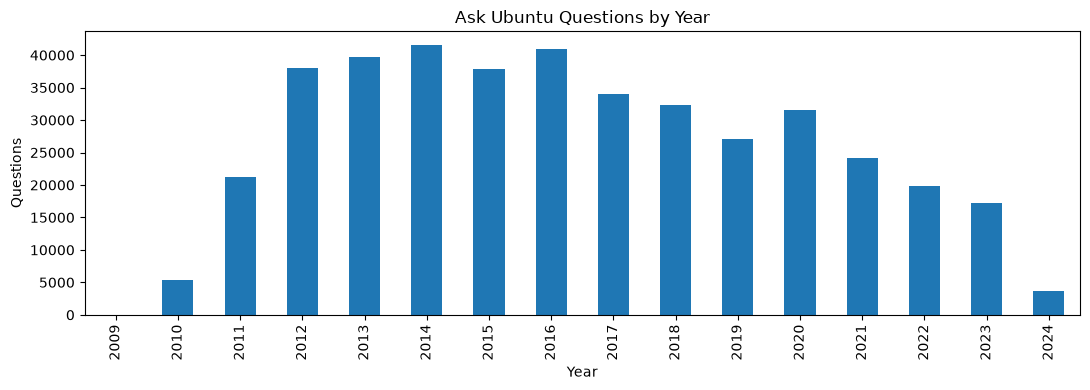

In [5]:
yearly = pd.Series(question_years).sort_index()
display(yearly.rename("Questions").to_frame())
ax = yearly.plot.bar(figsize=(11, 4), title="Ask Ubuntu Questions by Year")
ax.set(xlabel="Year", ylabel="Questions")
plt.tight_layout()
plt.show()

## 6. Tag Landscape

Identify the most frequently used tags across the dataset. These tags later inform the technical issue taxonomy.

,Tag,Questions
0,boot,24058
1,networking,22985
2,command-line,22509
3,14.04,20403
4,drivers,18196
5,dual-boot,17658
6,apt,17505
7,16.04,17210
8,12.04,16604
9,server,16499


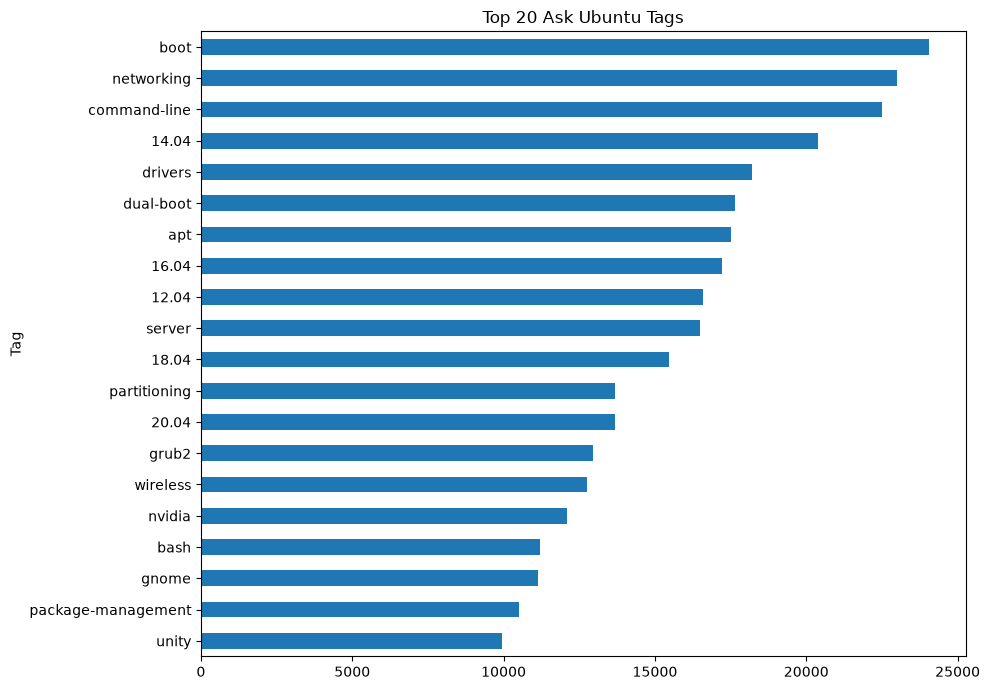

In [6]:
top_tags = pd.DataFrame(tag_counts.most_common(20), columns=["Tag", "Questions"])
display(top_tags)
ax = top_tags.iloc[::-1].plot.barh(x="Tag", y="Questions", figsize=(10, 7), legend=False,
                                  title="Top 20 Ask Ubuntu Tags")
plt.tight_layout()
plt.show()

## 7. Question–Answer Relationship Integrity

Verify that accepted-answer references are consistent: check for duplicate IDs, missing accepted answers, parent mismatches, and orphan answers.

In [7]:
import csv

question_ids = set()
accepted_links = {}
answer_parents = {}
with QUESTIONS.open(encoding="utf-8", newline="") as handle:
    for row in csv.DictReader(handle):
        if row["Id"] in question_ids:
            raise ValueError(f"Duplicate question ID: {row['Id']}")
        question_ids.add(row["Id"])
        if row["AcceptedAnswerId"]:
            accepted_links[row["Id"]] = row["AcceptedAnswerId"]
with ANSWERS.open(encoding="utf-8", newline="") as handle:
    for row in csv.DictReader(handle):
        if row["Id"] in answer_parents:
            raise ValueError(f"Duplicate answer ID: {row['Id']}")
        answer_parents[row["Id"]] = row["ParentId"]
missing_accepted = [(q, a) for q, a in accepted_links.items() if a not in answer_parents]
mismatched_accepted = [
    (q, a, answer_parents[a]) for q, a in accepted_links.items()
    if a in answer_parents and answer_parents[a] != q
]
orphan_answers = sum(parent not in question_ids for parent in answer_parents.values())
print("Accepted-answer references:", len(accepted_links))
print("Missing accepted answers:", len(missing_accepted))
print("Accepted answers with a different parent:", len(mismatched_accepted))
print("Answers without a question:", orphan_answers)
print("Missing pairs (question, answer):", missing_accepted)
print("Mismatched pairs (question, answer, actual parent):", mismatched_accepted)


Accepted-answer references: 136162
Missing accepted answers: 9
Accepted answers with a different parent: 2
Answers without a question: 0
Missing pairs (question, answer): [('7446', '7824'), ('24235', '24318'), ('1482111', '1509200'), ('1491958', '1509225'), ('1508950', '1509234'), ('1509058', '1509474'), ('1509116', '1509177'), ('1509122', '1509209'), ('1509149', '1509157')]
Mismatched pairs (question, answer, actual parent): [('6585', '6612', '4109'), ('28444', '28449', '19095')]


## Findings

### Dataset Size

- **414,451 questions** and **523,728 answers**.
- 318,557 questions have a positive AnswerCount.
- 136,162 questions have an AcceptedAnswerId.
- No blank titles, bodies, or tags were found.

### Tags and Temporal Coverage

- **3,162 distinct tags** covering networking, boot, drivers, command-line, and version-specific topics.
- Questions span from **2009 to 2024**.

### Answer Relationship Integrity

- 9 referenced accepted answers are absent from the answer dataset.
- 2 accepted answers have a ParentId that differs from the referring question.
- No orphan answers or duplicate IDs were found.
- A populated AcceptedAnswerId is not the same as a verified usable question–answer pair. These exceptions must be handled during data preparation.

### Extraction Fidelity

- All exported CSV fields were verified against the original Posts.xml and matched exactly, including HTML bodies, tags, and ContentLicense.

### Limitations

- Community answers may be outdated or environment-specific.
- Forum posts differ structurally from workplace support tickets.
- Detailed cleaning and final dataset preparation belong to M2.